# Ejercicio 5 Precios, rendimientos y estacionariedad del índice de París (2016–2023)

En este ejercicio se analizó la serie temporal del índice de París entre 2016 y 2023. Primero se cargaron y organizaron los datos de fechas y precios, después se calculó la serie de rendimientos porcentuales. Se graficaron ambas series y se aplicó la prueba de Dickey--Fuller aumentada (ADF) para evaluar su estacionariedad. Los resultados mostraron que la serie de precios no es estacionaria, mientras que la serie de rendimientos sí presenta estacionariedad.

In [97]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

Leemos el archivo

In [68]:
df_raw = pd.read_csv(r"Data/ParisIndex-2016-2023.csv",header=None)

In [73]:
df_raw

,1,2,3,4,5,6,7,8,9,10,...,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986
0,2016-01-04,2016-01-05,2016-01-06,2016-01-07,2016-01-08,2016-01-11,2016-01-12,2016-01-13,2016-01-14,2016-01-15,...,2023-09-18,2023-09-19,2023-09-20,2023-09-21,2023-09-22,2023-09-25,2023-09-26,2023-09-27,2023-09-28,2023-09-29
1,4522.4501953125,4537.6298828125,4480.47021484375,4403.580078125,4333.759765625,4312.740234375,4378.75,4391.93994140625,4312.89013671875,4210.16015625,...,7276.14013671875,7282.1201171875,7330.7900390625,7213.89990234375,7184.81982421875,7123.8798828125,7074.02001953125,7071.7900390625,7116.240234375,7135.06005859375


In [80]:
print(df_raw.iloc[0,:].info())
print(df_raw.iloc[1, :].info())

<class 'pandas.Series'>
Index: 1986 entries, 1 to 1986
Series name: 0
Non-Null Count  Dtype
--------------  -----
1986 non-null   str  
dtypes: str(1)
memory usage: 95.6 KB
None
<class 'pandas.Series'>
Index: 1986 entries, 1 to 1986
Series name: 1
Non-Null Count  Dtype
--------------  -----
1986 non-null   str  
dtypes: str(1)
memory usage: 95.6 KB
None


In [82]:
df = pd.DataFrame({"Fecha": pd.to_datetime(df_raw.iloc[0, :]),"Precio": pd.to_numeric(df_raw.iloc[1, :])})
df

,Fecha,Precio
1,2016-01-04,4522.450195
2,2016-01-05,4537.629883
3,2016-01-06,4480.470215
4,2016-01-07,4403.580078
5,2016-01-08,4333.759766
...,...,...
1982,2023-09-25,7123.879883
1983,2023-09-26,7074.020020
1984,2023-09-27,7071.790039
1985,2023-09-28,7116.240234


In [85]:
print(df.iloc[:, 0].info())
print(df.iloc[:, 1].info())

<class 'pandas.Series'>
Index: 1986 entries, 1 to 1986
Series name: Fecha
Non-Null Count  Dtype         
--------------  -----         
1986 non-null   datetime64[us]
dtypes: datetime64[us](1)
memory usage: 95.6 KB
None
<class 'pandas.Series'>
Index: 1986 entries, 1 to 1986
Series name: Precio
Non-Null Count  Dtype  
--------------  -----  
1986 non-null   float64
dtypes: float64(1)
memory usage: 95.6 KB
None


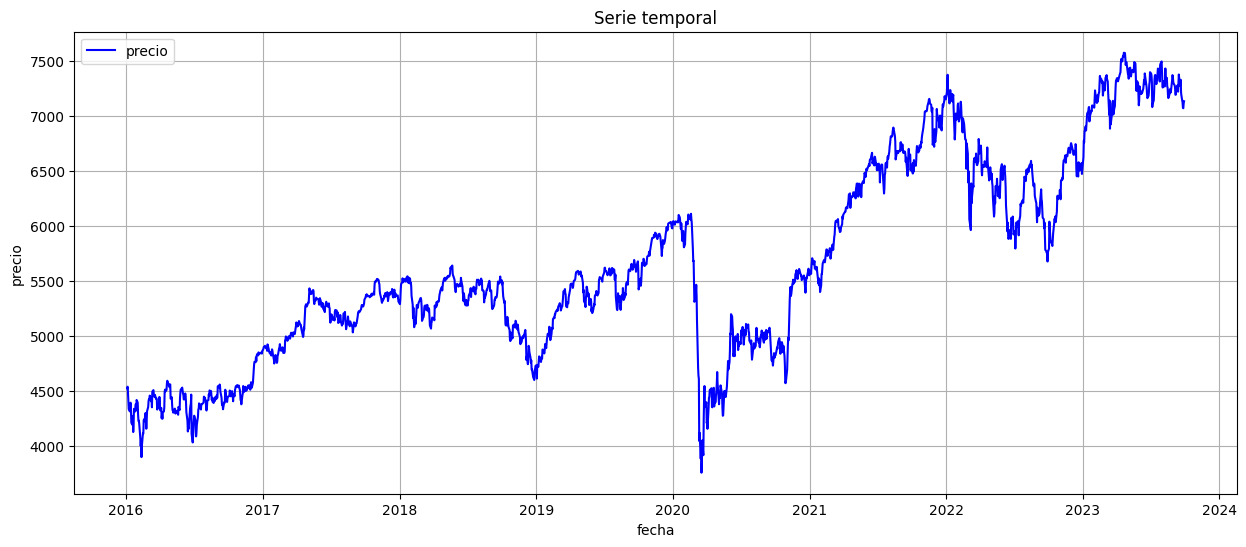

In [88]:
plt.figure(figsize=(15,6))
plt.plot(df.iloc[:, 0],df.iloc[:, 1], color = "blue", label = "precio")
plt.title("Serie temporal")
plt.xlabel("fecha")
plt.ylabel("precio")
plt.grid()
plt.legend(loc= "best")


## Calcular y graficar la serie temporal de rendimientos.

In [ ]:
df["Rendimiento"] = df["Precio"].pct_change()
df

,Fecha,Precio,Rendimiento
1,2016-01-04,4522.450195,NaN
2,2016-01-05,4537.629883,0.003357
3,2016-01-06,4480.470215,-0.012597
4,2016-01-07,4403.580078,-0.017161
5,2016-01-08,4333.759766,-0.015855
...,...,...,...
1982,2023-09-25,7123.879883,-0.008482
1983,2023-09-26,7074.020020,-0.006999
1984,2023-09-27,7071.790039,-0.000315
1985,2023-09-28,7116.240234,0.006286


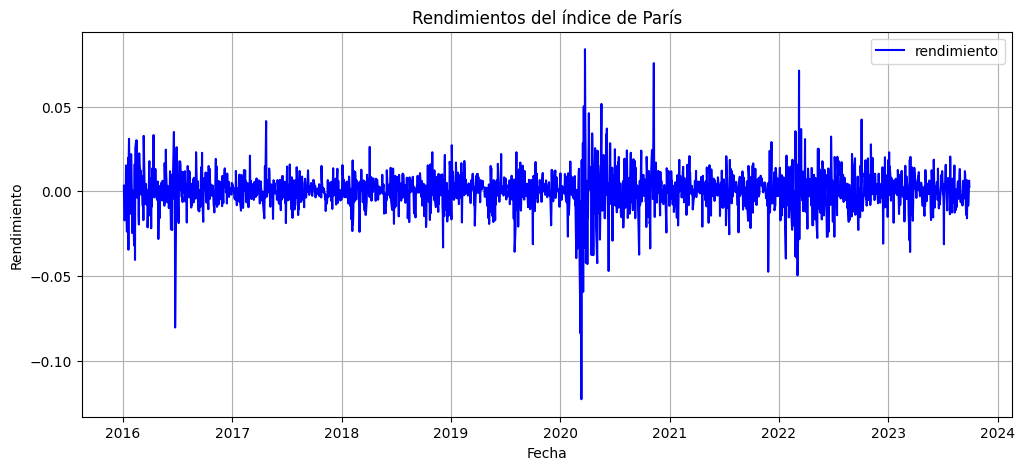

In [94]:
plt.figure(figsize=(12, 5))
plt.plot(df["Fecha"], df["Rendimiento"], label = "rendimiento", color = "blue")
plt.xlabel("Fecha")
plt.ylabel("Rendimiento")
plt.title("Rendimientos del índice de París")
plt.grid()
plt.legend(loc= "best")
plt.show()

In [98]:
adf_precio = adfuller(df["Precio"])

print("ADF Statistic:", adf_precio[0])
print("p-value:", adf_precio[1])

ADF Statistic: -1.4102512840912484
p-value: 0.5773517764243323


C:\Users\Piloto 01\AppData\Local\Temp\ipykernel_12404\3770111776.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_precio = adfuller(df["Precio"])


In [102]:
adf_rendimiento = adfuller(df["Rendimiento"].dropna())

print("ADF Statistic:", adf_rendimiento[0])
print("p-value:", adf_rendimiento[1])

ADF Statistic: -10.78074746194115
p-value: 2.258546899496092e-19


C:\Users\Piloto 01\AppData\Local\Temp\ipykernel_12404\1978115956.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_rendimiento = adfuller(df["Rendimiento"].dropna())


In [103]:
print("PRECIOS")
print("ADF Statistic:", adf_precio[0])
print("p-value:", adf_precio[1])
print("Valores críticos:", adf_precio[4])

print("\nRENDIMIENTOS")
print("ADF Statistic:", adf_rendimiento[0])
print("p-value:", adf_rendimiento[1])
print("Valores críticos:", adf_rendimiento[4])

PRECIOS
ADF Statistic: -1.4102512840912484
p-value: 0.5773517764243323
Valores críticos: {'1%': np.float64(-3.433648628001351), '5%': np.float64(-2.8629971502062155), '10%': np.float64(-2.5675457254979093)}

RENDIMIENTOS
ADF Statistic: -10.78074746194115
p-value: 2.258546899496092e-19
Valores críticos: {'1%': np.float64(-3.43368905179724), '5%': np.float64(-2.86301499720276), '10%': np.float64(-2.567555228165442)}


Se analizaron las series temporales de precios y rendimientos del índice de París durante el periodo 2016--2023. Para determinar su estacionariedad se aplicó la prueba de Dickey--Fuller aumentada (ADF), considerando un nivel de significancia de $\alpha = 0.05$. Para la serie de precios se obtuvo un estadístico ADF de aproximadamente $-1.4103$ y un valor $p = 0.5774$. Debido a que $p > 0.05$, no se rechaza la hipótesis nula de existencia de una raíz unitaria. Por lo tanto, la serie de precios se considera no estacionaria. Para la serie de rendimientos se obtuvo un estadístico ADF de aproximadamente $-10.7807$ y un valor $p \approx 2.26 \times 10^{-19}$. Como $p < 0.05$, se rechaza la hipótesis nula, por lo que existe evidencia de que la serie de rendimientos es estacionaria. Estos resultados son consistentes con las gráficas: los precios muestran variaciones en su nivel y una tendencia de largo plazo, mientras que los rendimientos fluctúan aproximadamente alrededor de cero.